# Classification of Early and Late Blight Potato Leaves

Tell Early blight from Late blight on potato leaves.

The method involves removing the background, extracting color, texture and shape features from the leaves, and training five classical machine learning models.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

from src.training.data import BASELINE, list_images, load_frames, split_features
from src.training.experiment import (
    best_per_model,
    error_overlap,
    evaluate_on_test,
    feature_importance,
    make_split,
    plot_errors,
    run_search,
    variant_comparison,
)
from src.training.plots import (
    plot_confusion_matrices,
    plot_feature_importance,
    plot_feature_space,
    show_samples,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

DATA_DIR = Path("data/Task 2 - Hard")
FOLDER_TO_LABEL = {'Potato___Early_blight': 0, 'Potato___Late_blight': 1}
LABEL_TO_NAME = {0: 'Early blight', 1: 'Late blight'}

## Data loading

Early blight    1000
Late blight     1000
Name: count, dtype: int64


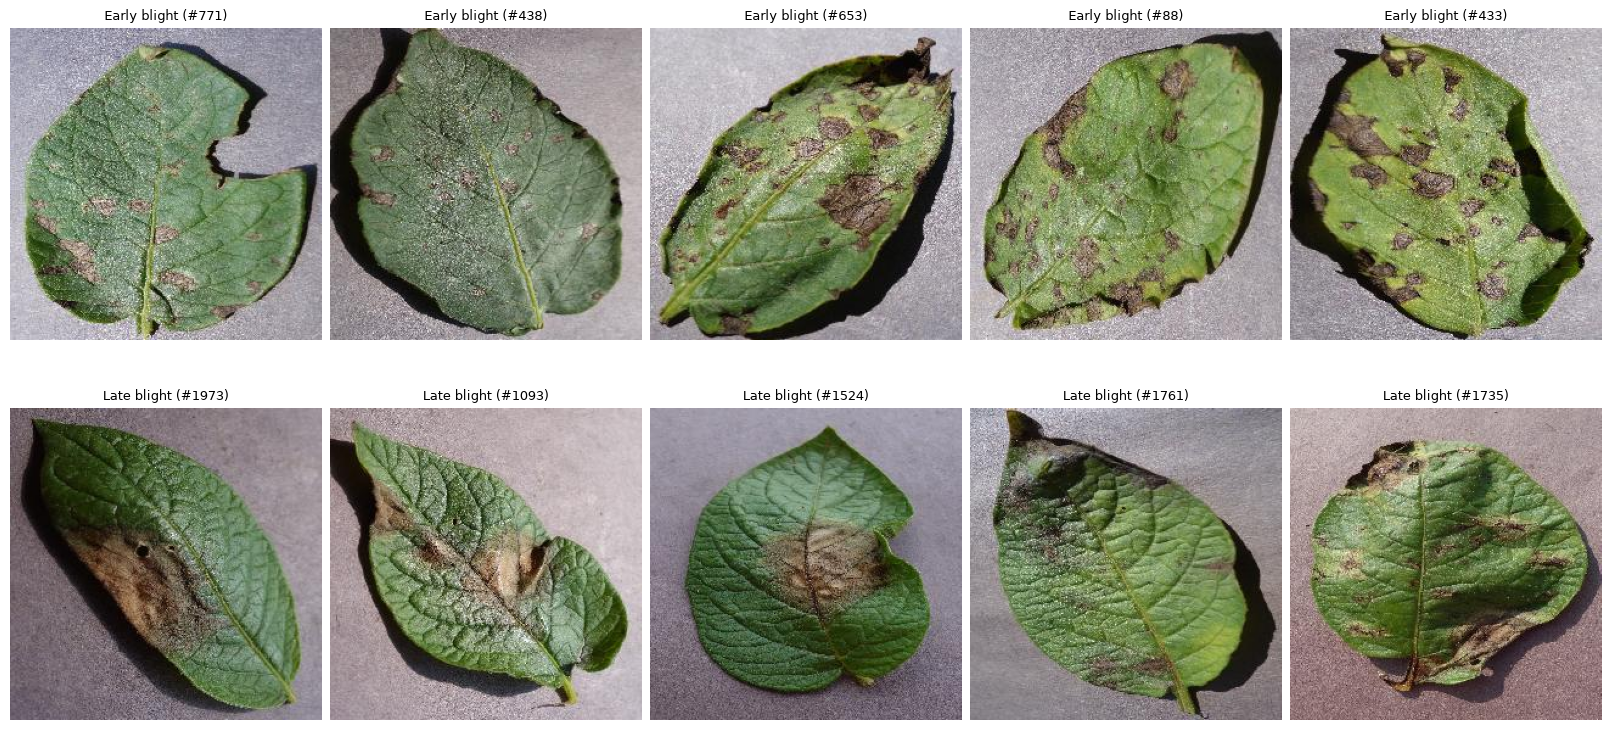

In [2]:
paths, labels = list_images(DATA_DIR, FOLDER_TO_LABEL)
print(pd.Series(labels).map(LABEL_TO_NAME).value_counts())
show_samples(paths, labels, LABEL_TO_NAME)

## Feature Extraction

The background is removed by masking everything outside the leaf.

We extract **50 features** divided into four groups:

| Group | Count | Description |
|---|---:|---|
| `color` | 6 | Mean and standard deviation of Lab color channels (L: lightness, a: green-red, b: blue-yellow) |
| `glcm` | 12 | Texture features based on neighbouring gray-level relationships |
| `lbp` | 28 | Local texture patterns calculated at two radii |
| `shape` | 4 | Features describing the leaf's outline |

We compare three preprocessing variants. Each removes the background before applying additional processing:

| Variant | Processing |
|---|---|
| `background_only` | Background removal only (baseline) |
| `normalized` | Background removal and min-max normalization |
| `filtered_clahe` | Background removal, Gaussian filtering (sigma = 0.5), CLAHE and min-max normalization |

In [3]:
frames = load_frames(DATA_DIR, FOLDER_TO_LABEL)
frames[BASELINE].head()

,sample_id,label,image_sha256,color_L_mean,color_L_std,color_a_mean,color_a_std,color_b_mean,color_b_std,glcm_d1_contrast,...,lbp_r2_12,lbp_r2_13,lbp_r2_14,lbp_r2_15,lbp_r2_16,lbp_r2_17,shape_eccentricity,shape_solidity,shape_extent,shape_circularity
0,Potato___Early_blight/001187a0-57ab-4329-baff-e7246a9edeb0___RS_Early.B 8178...,0,d7c117518ba397ffae96918a8316a47e210aeae421c6d078996dba14e60e8eff,43.733868,21.130831,-9.027969,8.652427,21.473316,11.699908,14.911448,...,0.017670,0.020557,0.032931,0.052710,0.090359,0.435079,0.527260,0.993705,0.666619,0.945574
1,Potato___Early_blight/002a55fb-7a3d-4a3a-aca8-ce2d5ebc6925___RS_Early.B 8170...,0,969ee287a4d92bd6ea985a279135edc80fba31a6c05b8260e9bf09a18d323e73,49.836700,21.088589,-10.955369,8.968112,22.370079,10.428775,12.893638,...,0.018124,0.020504,0.031710,0.051217,0.091478,0.413392,0.793967,0.994217,0.694214,0.857203
2,Potato___Early_blight/009c8c31-f22d-4ffd-8f16-189c6f06c577___RS_Early.B 7885...,0,177264705b2ac952ded2015d4b6f9f77c8605b2b01304c796a1b37ced429670f,50.471111,19.014990,-11.805661,6.185493,14.426441,6.544161,20.722851,...,0.008951,0.013400,0.027269,0.064920,0.108477,0.481604,0.817271,0.993282,0.680818,0.846625
3,Potato___Early_blight/00d8f10f-5038-4e0f-bb58-0b885ddc0cc5___RS_Early.B 8722...,0,9558d9a40dfd3d955bd9af16c992287324d848ddb0f61f7aa58c03a85106feec,44.817684,14.532833,-12.105601,4.216677,2.108108,4.219672,13.306764,...,0.013333,0.017502,0.031247,0.058058,0.100650,0.451105,0.800874,0.994661,0.700029,0.863796
4,Potato___Early_blight/0182e991-97f0-4805-a1f7-6e1b4306d518___RS_Early.B 7015...,0,d4d33da7f1f920e21d4c2218d970ff26b88865a06be6a3482e07ece90a9fc02f,52.065495,17.193720,-13.749977,6.414456,19.008503,7.291776,19.789467,...,0.013363,0.016381,0.030760,0.064076,0.100779,0.468947,0.717440,0.993215,0.683127,0.906787


## Train/test split

70% train, 30% test, stratified (same class ratio in both), seed 42.

In [4]:
split = make_split(frames)
print("duplicate images:", pd.Series(split.groups).duplicated().sum())
print(f"train: {len(split.train)}, test: {len(split.test)}")
print("share of class 1, train / test:", split.y_train.mean().round(3), split.y_test.mean().round(3))

duplicate images: 0
train: 1400, test: 600
share of class 1, train / test: 0.5 0.5


## Model Training and Validation

For each preprocessing variant and model, we perform a grid search using the training set.

- **Models:** SVM (RBF), SVM (linear), KNN, Random Forest and Logistic Regression.
- **Validation:** 5-fold cross-validation (CV) using the same folds for all models. Images of the same leaf are always kept in the same fold.
- **Scoring:** `f1_macro`.
- **Feature Scaling:** `StandardScaler` is applied before each model and fitted separately within each fold to prevent data leakage.

In [5]:
results, searches = run_search(frames, split)
results

,variant,model,cv_f1_macro,cv_std,best_params
0,filtered_clahe,SVM (RBF),0.972137,0.002673,"{'C': 10, 'gamma': 0.01}"
1,normalized,SVM (RBF),0.971427,0.002259,"{'C': 100, 'gamma': 0.001}"
2,background_only,SVM (RBF),0.971426,0.007143,"{'C': 1000, 'gamma': 0.001}"
3,background_only,Logistic Regression,0.968568,0.005251,{'C': 100}
4,background_only,SVM (linear),0.967855,0.002257,{'C': 1}
5,normalized,SVM (linear),0.967136,0.005256,{'C': 1}
6,normalized,Logistic Regression,0.965705,0.005811,{'C': 10}
7,filtered_clahe,SVM (linear),0.964994,0.009695,{'C': 10}
8,filtered_clahe,Logistic Regression,0.962849,0.007358,{'C': 10}
9,background_only,Random Forest,0.952135,0.009483,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}"


### Does more preprocessing help?

Best CV `f1_macro` for each model and variant.

In [6]:
variant_comparison(results)

variant,background_only,filtered_clahe,normalized
model,,,
KNN,0.9421,0.9235,0.9342
Logistic Regression,0.9686,0.9628,0.9657
Random Forest,0.9521,0.9443,0.9507
SVM (RBF),0.9714,0.9721,0.9714
SVM (linear),0.9679,0.9650,0.9671


## Model Evaluation

For each model, cross-validation selects the best configuration, including the preprocessing variant and hyperparameters. The selected configuration is then evaluated once on the test set.

- **Precision, Recall and F1:** Calculated for class 1 (ill leaf, Early Blight).
- **F1 Macro:** `test_f1_macro` is the average F1-score across both classes.

In [7]:
best = best_per_model(results)
metrics, predictions = evaluate_on_test(best, searches, frames, split)
winner = best.iloc[0]
display(metrics.round(3))
winner

,model,variant,cv_f1_macro,test_accuracy,test_precision,test_recall,test_f1,test_f1_macro
0,SVM (RBF),filtered_clahe,0.972,0.967,0.970,0.963,0.967,0.967
1,Logistic Regression,background_only,0.969,0.968,0.970,0.967,0.968,0.968
2,SVM (linear),background_only,0.968,0.963,0.960,0.967,0.963,0.963
3,Random Forest,background_only,0.952,0.948,0.947,0.950,0.948,0.948
4,KNN,background_only,0.942,0.933,0.951,0.913,0.932,0.933


variant                  filtered_clahe
model                         SVM (RBF)
cv_f1_macro                    0.972137
cv_std                         0.002673
best_params    {'C': 10, 'gamma': 0.01}
Name: 0, dtype: object

### Confusion matrices

Rows are the true class, columns the prediction.

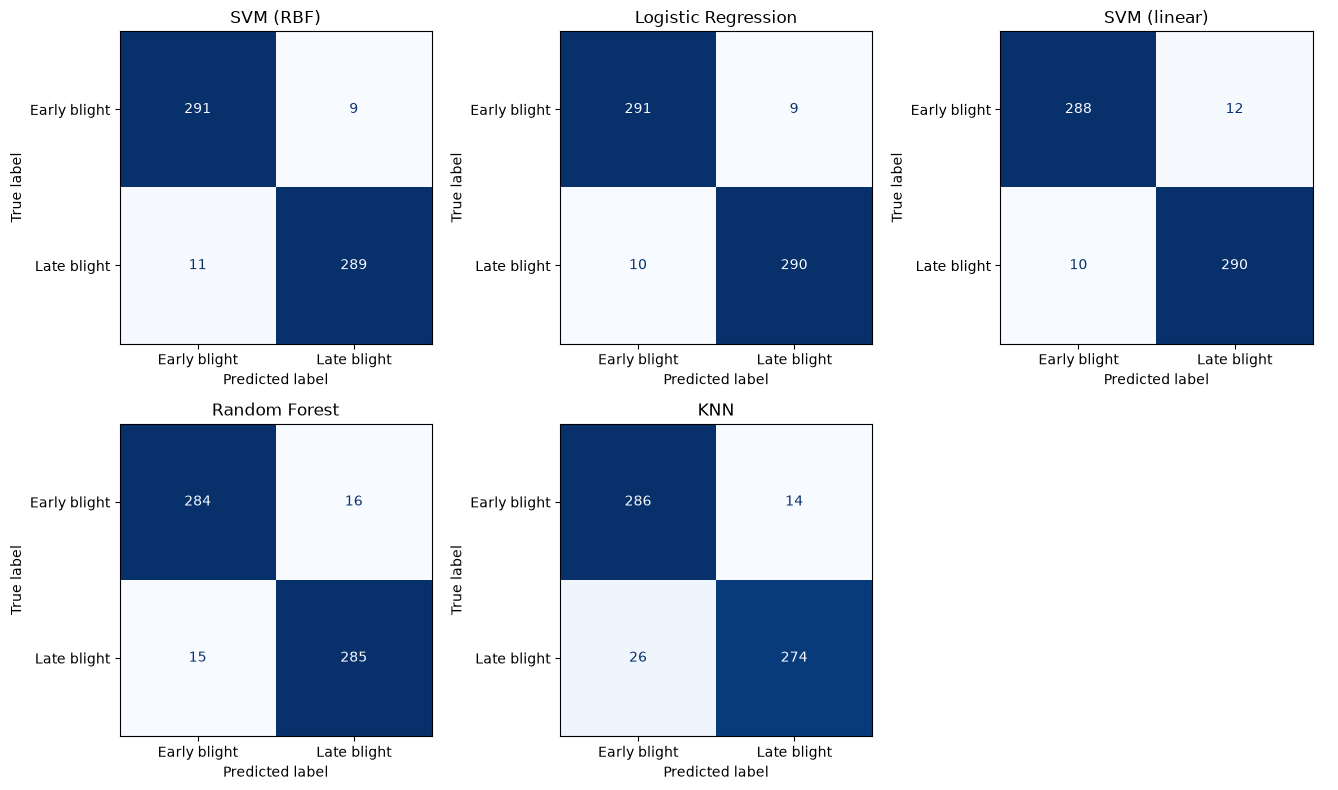

In [8]:
plot_confusion_matrices(predictions, split.y_test, LABEL_TO_NAME)

## Feature importance

We shuffle a feature (or a whole feature group) in the test set and measure how much the best model's `f1_macro` decreases. A bigger drop means greater importance.

- **Top row:** Importance of each feature group and the 10 most important individual features.
- **Bottom row:** The two most important features and a PCA plot showing all features reduced to two dimensions. PCA helps visualize class separation but is not a classifier.

Both plots use all images, not just the test set. Small differences may be noise. Feature groups are more reliable than individual features because correlated features can share importance.

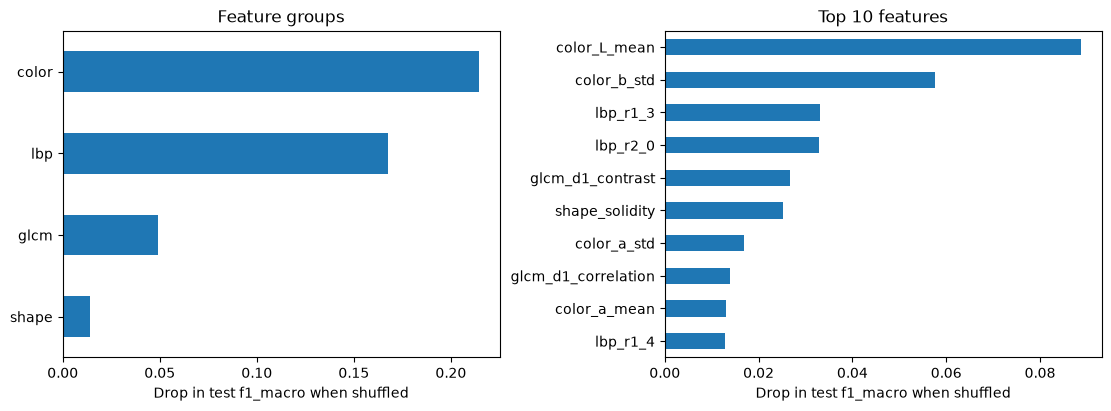

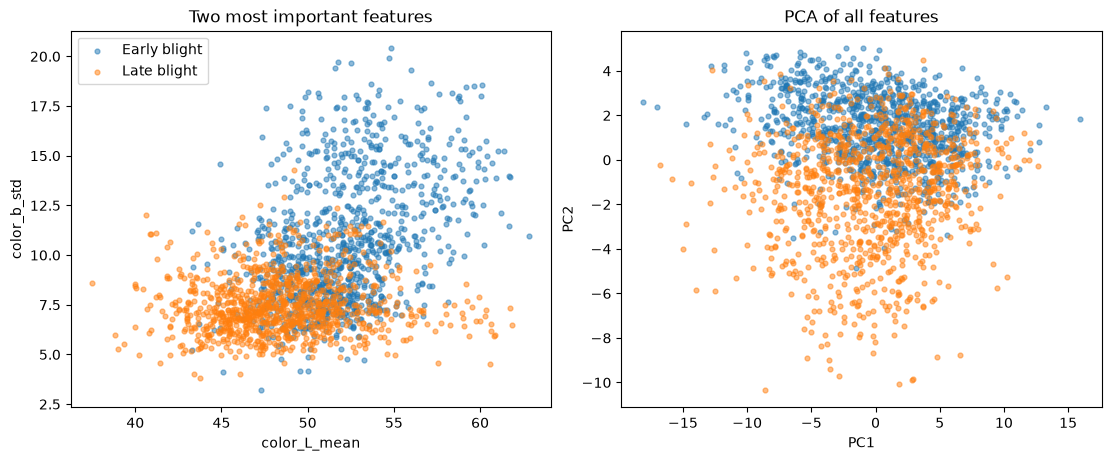

In [9]:
by_group, by_feature = feature_importance(winner, searches, frames, split)
plot_feature_importance(by_group, by_feature)

X, _ = split_features(frames[winner.variant])
plot_feature_space(X[by_feature.index], split.y, LABEL_TO_NAME, by_feature.index[::-1][:2])

## Misclassified test images

The test images that most models get wrong (up to 8), with the original next to the preprocessed version. A bad leaf mask would show as missing leaf or leftover background.

The table counts images missed by one, two or all models.

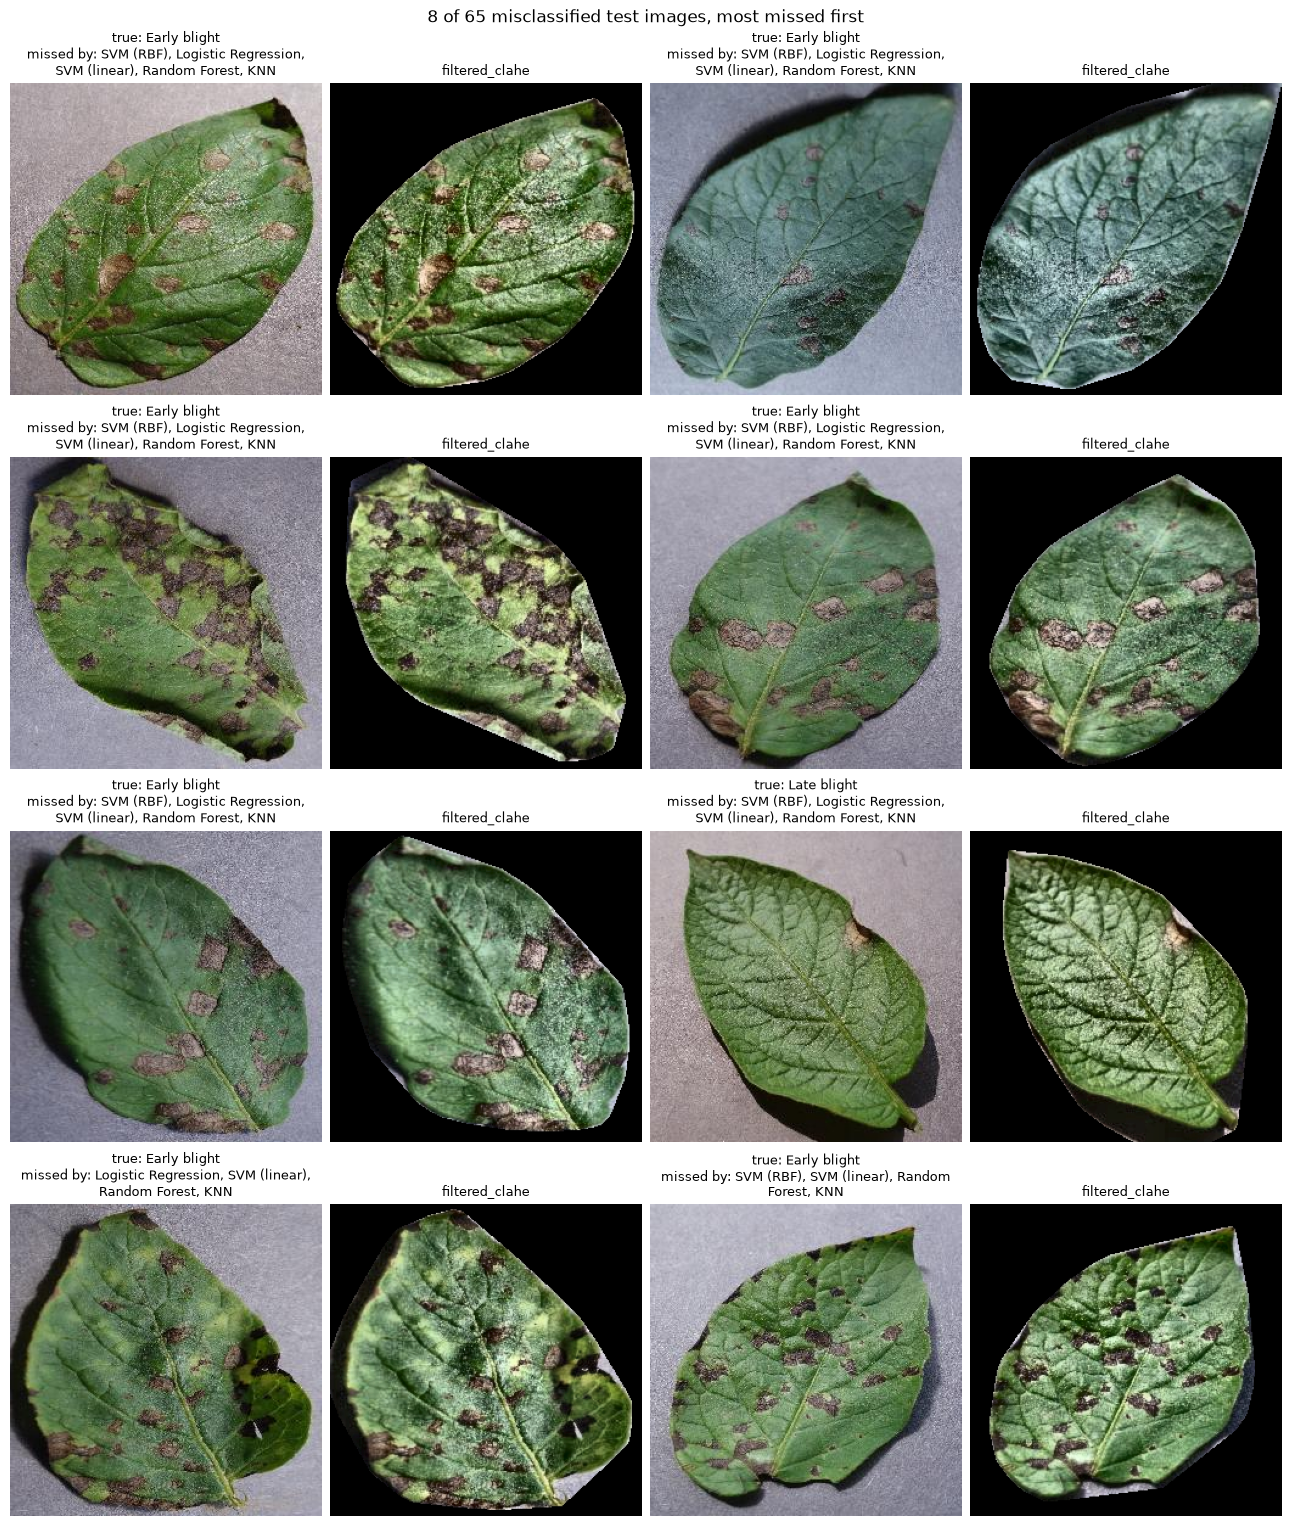

at least one model    65
two or more models    34
all 5 models           6
dtype: int64

In [10]:
plot_errors(best, predictions, frames, split, DATA_DIR, LABEL_TO_NAME)
error_overlap(predictions, split.y_test)

## Summary

RBF SVM achieves the best results, with 96.7% test accuracy. Logistic Regression and Linear SVM perform almost as well, while KNN gives the weakest results.

Color is the most important feature, followed by texture. Early blight leaves tend to be lighter and show greater color variation. However, the two classes still overlap.

Additional preprocessing does not improve the results. Background removal alone is sufficient.

Some images are difficult to classify, especially Early blight. Detecting individual lesions and extracting their area and number could improve the results.

The scores may be optimistic because different photos of the same leaf can appear in both training and test sets.